<a href="https://colab.research.google.com/github/Lahari-AIML-max/drug-classification-ml/blob/main/Drug_classfication_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('/content/drug200.csv')

df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


In [3]:
df.shape

(200, 6)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    object 
 2   BP           200 non-null    object 
 3   Cholesterol  200 non-null    object 
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 9.5+ KB


In [6]:
df.isnull().sum()

,0
Age,0
Sex,0
BP,0
Cholesterol,0
Na_to_K,0
Drug,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
# 1. Summary statistics
print("SUMMARY STATISTICS")
display(df.describe())

# 2. Count values in categorical columns
print("\nSEX DISTRIBUTION")
display(df["Sex"].value_counts())

print("\nBLOOD PRESSURE DISTRIBUTION")
display(df["BP"].value_counts())

print("\nCHOLESTEROL DISTRIBUTION")
display(df["Cholesterol"].value_counts())

# 3. Check the target classes
print("\nDRUG CLASS DISTRIBUTION")
display(df["Drug"].value_counts())

# 4. Check the dataset again
print("\nDATASET SHAPE:", df.shape)

SUMMARY STATISTICS


,Age,Na_to_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000



SEX DISTRIBUTION


,count
Sex,
M,104
F,96



BLOOD PRESSURE DISTRIBUTION


...


CHOLESTEROL DISTRIBUTION


,count
Cholesterol,
HIGH,103
NORMAL,97



DRUG CLASS DISTRIBUTION


,count
Drug,
drugY,91
drugX,54
drugA,23
drugC,16
drugB,16



DATASET SHAPE: (200, 6)


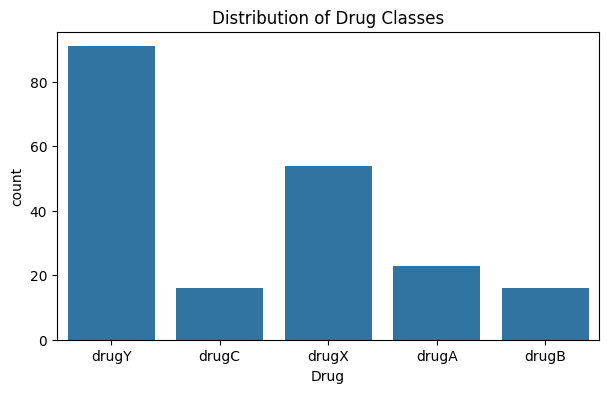

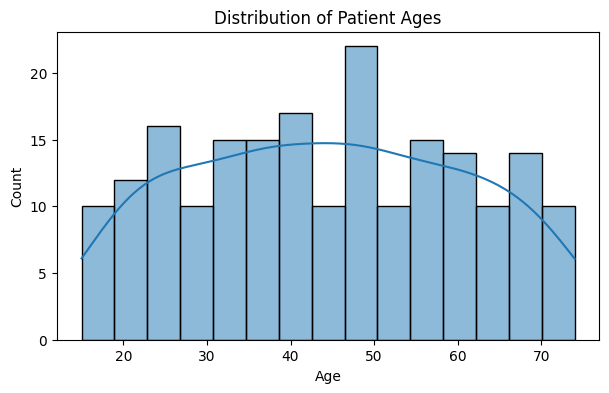

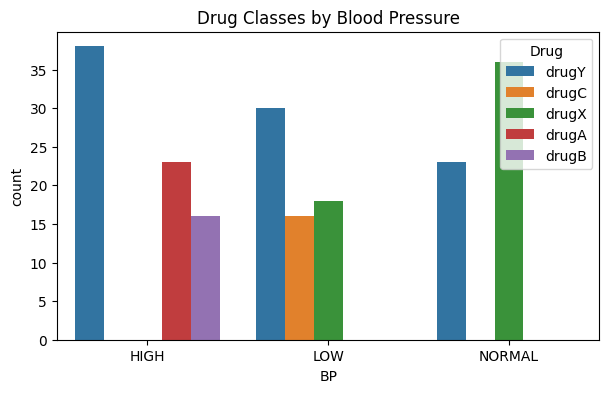

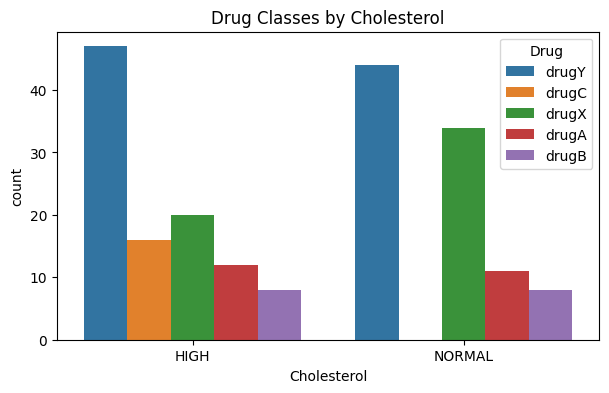

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Distribution of drug classes
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Drug")
plt.title("Distribution of Drug Classes")
plt.show()

# 2. Age distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Age", bins=15, kde=True)
plt.title("Distribution of Patient Ages")
plt.show()

# 3. Drug classes by blood pressure
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="BP", hue="Drug")
plt.title("Drug Classes by Blood Pressure")
plt.show()

# 4. Drug classes by cholesterol
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Cholesterol", hue="Drug")
plt.title("Drug Classes by Cholesterol")
plt.show()

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Separate input features and target
X = df.drop("Drug", axis=1)
y = df["Drug"]

# Encode categorical input columns
X = pd.get_dummies(
    X,
    columns=["Sex", "BP", "Cholesterol"],
    dtype=int
)

# Encode target drug labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Original dataset shape:", df.shape)
print("Processed features shape:", X.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Drug label mapping:")

for number, drug in enumerate(label_encoder.classes_):
    print(number, "=", drug)

Original dataset shape: (200, 6)
Processed features shape: (200, 9)
Training features: (160, 9)
Testing features: (40, 9)
Drug label mapping:
0 = drugA
1 = drugB
2 = drugC
3 = drugX
4 = drugY
